# Phase 3 — Plain KD student + "where does compression hurt?"
**Mixing-Aware Distillation for Hinglish**

Needs the Phase 2 outputs (`teacher_best/`, split UID files, teacher probabilities).
**Run Phase 2's folder through Drive first**: `/content/phase2_outputs` disappears when the Colab runtime resets.

What this notebook does
1. Rebuilds the exact Phase 2 splits and verifies the saved teacher reproduces its Phase 2 test score.
2. Builds an unlabeled transfer set from L3Cube-HingLID (with gold language tags, so Phase 4 gets noise-free CMI).
3. Builds a 6-layer student from the teacher (optional vocabulary trimming).
4. Trains arms: `ce_only` (no teacher), `kd_plain` (logit + hidden-state KD), optionally `kd_logits`, `kd_labeled`.
5. Reports student vs teacher macro-F1 per CMI / switch-density / length bin with PAIRED bootstrap CIs,
   and tests whether the student-teacher gap grows with mixing (the project's central question).

Copy everything under `════ REPORT BACK ════` markers and send it back.

In [1]:
# CELL 1: Imports, config, locate Phase 2 outputs
import os, sys, re, json, time, copy, random, shutil, subprocess, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ── Config ───────────────────────────────────────────────────────────────────
SEEDS        = [13, 42, 2024]
RUN_ARMS     = ["ce_only", "kd_plain"]          # optional ablations: add "kd_logits", "kd_labeled"
EPOCHS       = 3
LR           = 5e-5
BATCH        = 32
MAXLEN       = 160
WARMUP_FRAC  = 0.10
WEIGHT_DECAY = 0.01
TEMP         = 2.0                              # KD temperature
LAYER_MAP    = [1, 3, 5, 7, 9, 11]              # teacher layers (0-indexed) copied into the 6 student layers.
                                                # Odd layers so the LAST student layer matches the teacher's final layer.
                                                # (Phase 1 planned [0,2,4,6,8,10]; set that here to revert.)
TRIM_VOCAB       = True
VOCAB_MIN_COUNT  = 2                            # keep wordpieces seen >=2x in train+dev+transfer (test is NOT used)
MIN_LANG_TOKENS  = 4                            # transfer-set filter
N_TRANSFER_MAX   = None                         # e.g. 20000 to speed up; None = use all
N_BOOT       = 1000
MIN_BIN_N    = 50
USE_DRIVE    = True

ARMS = {   # alpha = weight on gold-label CE; (1-alpha) on logit KL; beta = weight on hidden-state MSE
    "ce_only":    dict(alpha=1.0, beta=0.0, use_kl=False, unlabeled=False, teacher=False),
    "kd_labeled": dict(alpha=0.5, beta=1.0, use_kl=True,  unlabeled=False, teacher=True),
    "kd_logits":  dict(alpha=0.5, beta=0.0, use_kl=True,  unlabeled=True,  teacher=True),
    "kd_plain":   dict(alpha=0.5, beta=1.0, use_kl=True,  unlabeled=True,  teacher=True),
}
LABELS = ["negative", "neutral", "positive"]; LABEL2ID = {l: i for i, l in enumerate(LABELS)}; K = 3

# DRIVE_ROOT = Path("/content/drive/MyDrive/mixing_aware_kd")
# drive_ok = False
# if USE_DRIVE:
#     try:
#         from google.colab import drive
#         drive.mount("/content/drive"); drive_ok = True
#     except Exception as e:
#         print(f"(Drive not mounted: {type(e).__name__})")

# def find_phase2():
#     for c in [DRIVE_ROOT / "phase2", Path("/content/phase2_outputs"), Path("./phase2_outputs")]:
#         if (c / "split_train_uids.csv").exists() and ((c / "teacher_best").exists() or (c / "teacher_best_model").exists()):
#             return c
#     return None

# P2 = find_phase2()
# if P2 is None:
#     raise FileNotFoundError("Phase 2 outputs not found (need teacher_best/ and split_*_uids.csv). "
#                             "If the runtime was reset, re-run the Phase 2 notebook with USE_DRIVE=True.")
# if drive_ok and not str(P2).startswith(str(DRIVE_ROOT)):          # back up local Phase 2 outputs to Drive
#     dst = DRIVE_ROOT / "phase2"; dst.mkdir(parents=True, exist_ok=True)
#     shutil.copytree(P2, dst, dirs_exist_ok=True); print(f"Backed up Phase 2 outputs to {dst}"); P2 = dst
# TEACHER_DIR = P2 / ("teacher_best" if (P2 / "teacher_best").exists() else "teacher_best_model")
# OUT_DIR = (DRIVE_ROOT / "phase3") if drive_ok else Path("./phase3_outputs")
# OUT_DIR.mkdir(parents=True, exist_ok=True); (OUT_DIR / "figures").mkdir(exist_ok=True)
# DATA_DIR = Path("./data"); DATA_DIR.mkdir(exist_ok=True)
# p2_summary = json.loads((P2 / "phase2_summary.json").read_text())
# BEST_T_SEED = p2_summary["best_seed_for_phase3"]
# print(f"Phase 2 dir: {P2}\nTeacher: {TEACHER_DIR} (seed {BEST_T_SEED})\nPhase 3 outputs: {OUT_DIR}")

# ── Config ───────────────────────────────────────────────────────────────────
USE_DRIVE = False

P2 = Path("/content/phase2_outputs")

if not P2.exists():
    raise FileNotFoundError(f"Phase 2 directory not found: {P2}")

if not (P2 / "split_train_uids.csv").exists():
    raise FileNotFoundError(f"Missing split_train_uids.csv in {P2}")

if (P2 / "teacher_best").exists():
    TEACHER_DIR = P2 / "teacher_best"
elif (P2 / "teacher_best_model").exists():
    TEACHER_DIR = P2 / "teacher_best_model"
else:
    raise FileNotFoundError(f"Teacher model directory not found in {P2}")

OUT_DIR = Path("/content/phase3_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "figures").mkdir(exist_ok=True)

DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

p2_summary = json.loads((P2 / "phase2_summary.json").read_text())
BEST_T_SEED = p2_summary["best_seed_for_phase3"]

print(f"Phase 2 dir: {P2}")
print(f"Teacher: {TEACHER_DIR} (seed {BEST_T_SEED})")
print(f"Phase 3 outputs: {OUT_DIR}")


try:
    import torch, torch.nn.functional as F
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    torch = None; F = None; DEVICE = "cpu"
print("Device:", DEVICE)
if str(DEVICE) == "cpu": print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU.")

Phase 2 dir: /content/phase2_outputs
Teacher: /content/phase2_outputs/teacher_best (seed 2024)
Phase 3 outputs: /content/phase3_outputs
Device: cuda


In [2]:
# CELL 2: Rebuild the Phase 2 splits + gold CMI metrics; sanity-check against Phase 2 files
URL_RE = re.compile(r"^(https?://|www\.)\S+$", re.I); MENTION_RE = re.compile(r"^@\w+$")
HASHTAG_RE = re.compile(r"^#\w+"); NONWORD_RE = re.compile(r"^[\d\W_]+$")

def parse_semeval_conll(path):
    sents, cur = [], None
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if line.startswith("meta\t"):
                if cur is not None: sents.append(cur)
                p = line.split("\t")
                cur = {"uid": p[1].strip(), "label": (p[2].strip() if len(p) > 2 and p[2].strip() else None),
                       "tokens": [], "raw_tags": []}
            elif not line.strip(): continue
            elif cur is not None:
                p = line.split("\t"); cur["tokens"].append(p[0]); cur["raw_tags"].append(p[1].strip() if len(p) > 1 else "")
    if cur is not None: sents.append(cur)
    return sents

def norm_gold_tag(t):
    t = re.sub(r"[^A-Za-z]", "", t).lower()
    return "HI" if t.startswith("hin") else "EN" if t.startswith("eng") else "OTHER"

def independent_mask(tokens):
    m = [False] * len(tokens)
    for i, t in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if URL_RE.match(t) or MENTION_RE.match(t) or HASHTAG_RE.match(t) or NONWORD_RE.match(t) or prev in ("@", "#"):
            m[i] = True
    return m

def finalize_tags(tokens, base_tags):
    m = independent_mask(tokens); return ["OTHER" if m[i] else base_tags[i] for i in range(len(tokens))]

def build_text(tokens):
    out, i = [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens): out.append("@user"); i += 2; continue
        out.append("http" if URL_RE.match(t) else t); i += 1
    return " ".join(out)

def compute_cmi(tags):
    lang = [t for t in tags if t in ("HI", "EN")]; n, u = len(tags), len(tags) - len(lang)
    if (n - u) <= 1: return 0.0
    return (len(lang) - max(Counter(lang).values())) / (n - u)

def compute_sd(tags):
    lang = [t for t in tags if t in ("HI", "EN")]
    if len(lang) <= 1: return 0.0
    return sum(lang[i] != lang[i + 1] for i in range(len(lang) - 1)) / (len(lang) - 1)

def abs_cmi_bin(c):
    return "mono" if c == 0 else "low" if c < 0.20 else "mid" if c < 0.35 else "high"
ABS_ORDER = ["mono", "low", "mid", "high"]

def quantile_bins(x, q=5):
    x = np.asarray(x, float); edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    if len(edges) < 3: return np.zeros(len(x), int), ["all"]
    idx = np.clip(np.digitize(x, edges[1:-1], right=False), 0, len(edges) - 2)
    labels = [f"Q{i+1} [{edges[i]:.2f},{edges[i+1]:.2f}{']' if i == len(edges)-2 else ')'}" for i in range(len(edges) - 1)]
    return idx, labels

def macro_f1_np(y, p, k=K):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros(k), where=den > 0); present = cm.sum(1) > 0
    return float(f1[present].mean()) if present.any() else float("nan")

def to_df(sents):
    df = pd.DataFrame(sents)
    df["gold_tags"] = [finalize_tags(t, [norm_gold_tag(x) for x in rt]) for t, rt in zip(df["tokens"], df["raw_tags"])]
    df["text"] = df["tokens"].apply(build_text); df["raw_text"] = df["tokens"].apply(lambda t: " ".join(t))
    return df

def add_gold_metrics(df):
    df["cmi_gold"] = [compute_cmi(t) for t in df.gold_tags]; df["sd_gold"] = [compute_sd(t) for t in df.gold_tags]
    df["nlang_gold"] = [sum(x in ("HI", "EN") for x in t) for t in df.gold_tags]; return df

SEMEVAL_DIR = DATA_DIR / "semeval"
if not SEMEVAL_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/singhnivedita/SemEval2020-Task9.git", str(SEMEVAL_DIR)], capture_output=True)
ORIG = SEMEVAL_DIR / "Pre Processing Code" / "Original Dataset"; TY = SEMEVAL_DIR / "Fully Processed Datasets" / "Ty.txt"
raw_train, raw_val, raw_test = [to_df(parse_semeval_conll(ORIG / f)) for f in ["Train.txt", "Validation.txt", "Test.txt"]]
ty = pd.read_csv(TY, dtype=str); raw_test["label"] = raw_test["uid"].map(dict(zip(ty["Uid"].str.strip(), ty["Sentiment"].str.strip().str.lower())))
all_df = pd.concat([raw_train, raw_val], ignore_index=True).drop_duplicates("uid")

def from_split(csv):
    s = pd.read_csv(P2 / csv, dtype={"uid": str}); d = s[["uid"]].merge(all_df, on="uid", how="left")
    assert d["tokens"].notna().all(), f"{csv}: some UIDs not found in raw data"
    d["y"] = d["label"].map(LABEL2ID); assert (d["y"].values == s["y"].values).all(), f"{csv}: labels differ from Phase 2"
    return add_gold_metrics(d)

tr_df, dev_df = from_split("split_train_uids.csv"), from_split("split_dev_uids.csv")
te_df = add_gold_metrics(raw_test.reset_index(drop=True)); te_df["y"] = te_df["label"].map(LABEL2ID)
y_te = te_df.y.values.astype(int)

p2pred = pd.read_csv(P2 / "teacher_test_predictions.csv", dtype={"uid": str})
assert (p2pred.uid.values == te_df.uid.values).all(), "Test order differs from Phase 2"
cmi_diff = np.abs(p2pred.iloc[:, p2pred.columns.get_loc("cmi_gold")].values - te_df.cmi_gold.values).max() if "cmi_gold" in p2pred else float("nan")
P_T_ALL = np.load(P2 / "teacher_test_probs_all_seeds.npy")                       # (S,N,K) Phase 2 seeds
P_T = np.load(P2 / f"seed{BEST_T_SEED}_test_probs.npy").argmax(1)                # frozen teacher predictions (N,)
print(f"train={len(tr_df)} dev={len(dev_df)} test={len(te_df)} | max |CMI diff vs Phase 2| = {cmi_diff:.2e}")
print(f"Frozen teacher (seed {BEST_T_SEED}) test macro-F1 from Phase 2 file = {macro_f1_np(y_te, P_T):.4f}")

train=13931 dev=1548 test=3000 | max |CMI diff vs Phase 2| = 9.71e-17
Frozen teacher (seed 2024) test macro-F1 from Phase 2 file = 0.7337


In [3]:
# CELL 3: Unlabeled transfer set from L3Cube-HingLID (gold HI/EN tags kept for Phase 4)
import urllib.request
LID_DIR = DATA_DIR / "L3Cube-HingLID"; LID_DIR.mkdir(exist_ok=True)
BASE = "https://raw.githubusercontent.com/l3cube-pune/code-mixed-nlp/main/L3Cube-HingLID"
def parse_hinglid(fp):
    sents, toks, tags = [], [], []
    with open(fp, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if not line.strip():
                if toks: sents.append((toks, tags)); toks, tags = [], []
                continue
            p = line.split("\t")
            if len(p) >= 2: toks.append(p[0]); tags.append("HI" if p[-1].strip().upper().startswith("HI") else "EN")
    if toks: sents.append((toks, tags))
    return sents
hl = []
for split in ["train", "validation"]:                         # HingLID test is left untouched for tagger work
    fp = LID_DIR / f"{split}.txt"
    if not fp.exists(): urllib.request.urlretrieve(f"{BASE}/{split}.txt", str(fp))
    hl += parse_hinglid(fp)

test_texts = set(raw_test.raw_text.str.lower())
rows, seen = [], set()
for toks, base in hl:
    key = " ".join(toks).lower()
    if key in seen or key in test_texts: continue
    seen.add(key); tags = finalize_tags(toks, base)
    nl = sum(t in ("HI", "EN") for t in tags)
    if nl < MIN_LANG_TOKENS: continue
    rows.append({"uid": f"hl{len(rows)}", "tokens": toks, "gold_tags": tags, "text": build_text(toks), "y": -1,
                 "cmi_gold": compute_cmi(tags), "sd_gold": compute_sd(tags), "nlang_gold": nl})
transfer = pd.DataFrame(rows)
if N_TRANSFER_MAX and len(transfer) > N_TRANSFER_MAX: transfer = transfer.sample(N_TRANSFER_MAX, random_state=0).reset_index(drop=True)
t_save = transfer.copy(); t_save["tokens"] = t_save.tokens.apply(json.dumps); t_save["gold_tags"] = t_save.gold_tags.apply(json.dumps)
t_save.to_csv(OUT_DIR / "transfer_set.csv.gz", index=False)

print("=" * 70); print("════ REPORT BACK: TRANSFER SET ════"); print("=" * 70)
print(f"HingLID sentences read: {len(hl)} -> kept {len(transfer)} (dedup, no exact test-text matches, >= {MIN_LANG_TOKENS} language tokens)")
cmp = pd.DataFrame({"set": ["SemEval train (labeled)", "HingLID transfer (unlabeled)"],
                    "n": [len(tr_df), len(transfer)],
                    "mean_CMI": [tr_df.cmi_gold.mean(), transfer.cmi_gold.mean()],
                    "mean_SD": [tr_df.sd_gold.mean(), transfer.sd_gold.mean()],
                    "mean_lang_tokens": [tr_df.nlang_gold.mean(), transfer.nlang_gold.mean()]})
print(cmp.round(3).to_string(index=False))
print("CMI bin shares (%):")
for nm, d in [("SemEval", tr_df), ("HingLID", transfer)]:
    print(f"  {nm:8s}", (d.cmi_gold.apply(abs_cmi_bin).value_counts(normalize=True).reindex(ABS_ORDER).fillna(0) * 100).round(1).to_dict())
print("Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.")

════ REPORT BACK: TRANSFER SET ════
HingLID sentences read: 38035 -> kept 37584 (dedup, no exact test-text matches, >= 4 language tokens)
                         set     n  mean_CMI  mean_SD  mean_lang_tokens
     SemEval train (labeled) 13931     0.277    0.187            19.235
HingLID transfer (unlabeled) 37584     0.262    0.317            30.209
CMI bin shares (%):
  SemEval  {'mono': 0.6, 'low': 26.3, 'mid': 45.1, 'high': 28.0}
  HingLID  {'mono': 0.0, 'low': 32.6, 'mid': 43.3, 'high': 24.1}
Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.


In [5]:
from pathlib import Path
from safetensors import safe_open

def ok(d):
    try:
        with safe_open(str(Path(d)/"model.safetensors"), framework="pt") as sf:
            ks = list(sf.keys()); sf.get_tensor(ks[0]); sf.get_tensor(ks[-1])
        return True
    except Exception as e:
        print("unreadable:", d, str(e)[:60]); return False

for d in ["/content/phase2_outputs/teacher_best",
          "/content/drive/MyDrive/mixing_aware_kd/phase2/teacher_best"]:
    if Path(d).exists() and ok(d):
        TEACHER_DIR = Path(d); print("Using", TEACHER_DIR); break
else:
    print("No readable copy found: see the retrain steps below")

Using /content/phase2_outputs/teacher_best


In [6]:
# CELL 4: Load teacher, tokenize everything, verify teacher reproduces Phase 2
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
for p_ in teacher.parameters(): p_.requires_grad_(False)
USE_AMP = str(DEVICE) == "cuda"

def encode(texts): return tok(list(texts), truncation=True, max_length=MAXLEN)
enc = {n: encode(d.text) for n, d in [("tr", tr_df), ("dev", dev_df), ("te", te_df), ("tf", transfer)]}

class DS(torch.utils.data.Dataset):
    def __init__(self, enc_, y, w=None):
        self.enc, self.y, self.keys = enc_, list(y), list(enc_.keys()); self.w = np.ones(len(self.y)) if w is None else np.asarray(w, float)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}; item["labels"] = int(self.y[i]); item["ex_w"] = float(self.w[i]); return item

def collate(batch):
    labels = torch.tensor([b.pop("labels") for b in batch]); w = torch.tensor([b.pop("ex_w") for b in batch], dtype=torch.float)
    out = tok.pad(batch, return_tensors="pt"); out["labels"] = labels; out["ex_w"] = w; return out

def merge_enc(a, b):
    return {k: list(a[k]) + list(b[k]) for k in a.keys()}

@torch.no_grad()
def predict_probs(model, loader, remap=None):
    model.eval(); outs = []
    for b in loader:
        ids = b["input_ids"].to(DEVICE)
        if remap is not None: ids = remap[ids]
        kw = {"input_ids": ids, "attention_mask": b["attention_mask"].to(DEVICE)}
        if "token_type_ids" in b: kw["token_type_ids"] = b["token_type_ids"].to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**kw).logits
        outs.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(outs)

te_loader = torch.utils.data.DataLoader(DS(enc["te"], te_df.y), batch_size=128, collate_fn=collate)
dev_loader = torch.utils.data.DataLoader(DS(enc["dev"], dev_df.y), batch_size=128, collate_fn=collate)
chk = predict_probs(teacher, te_loader)
agree = float((chk.argmax(1) == P_T).mean())
print("=" * 70); print("════ REPORT BACK: TEACHER REPRODUCTION CHECK ════"); print("=" * 70)
print(f"Reloaded teacher test macro-F1 = {macro_f1_np(y_te, chk.argmax(1)):.4f}  vs Phase 2 file {macro_f1_np(y_te, P_T):.4f}; "
      f"prediction agreement = {agree:.2%} (expect ~99-100%; small diffs are fp16 rounding)")
assert agree > 0.97, "Loaded teacher does not match Phase 2 predictions: wrong checkpoint or tokenizer?"

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

════ REPORT BACK: TEACHER REPRODUCTION CHECK ════
Reloaded teacher test macro-F1 = 0.7337  vs Phase 2 file 0.7337; prediction agreement = 100.00% (expect ~99-100%; small diffs are fp16 rounding)


In [7]:
# CELL 5: Vocabulary trimming + 6-layer student builder
V = teacher.config.vocab_size
special = sorted(set(tok.all_special_ids)); unk_id = tok.unk_token_id
if TRIM_VOCAB:
    all_ids = np.concatenate([np.array(x, dtype=np.int64) for n in ["tr", "dev", "tf"] for x in enc[n]["input_ids"]])
    counts = np.bincount(all_ids, minlength=V)
    kept = np.array(sorted(set(special) | set(np.where(counts >= VOCAB_MIN_COUNT)[0].tolist())), dtype=np.int64)
else:
    kept = np.arange(V)
unk_new = int(np.where(kept == unk_id)[0][0])
remap_np = np.full(V, unk_new, dtype=np.int64); remap_np[kept] = np.arange(len(kept))
remap_t = torch.tensor(remap_np, device=DEVICE)
np.save(OUT_DIR / "kept_ids.npy", kept)
test_ids = np.concatenate([np.array(x, dtype=np.int64) for x in enc["te"]["input_ids"]])
oov = float(np.mean((remap_np[test_ids] == unk_new) & (test_ids != unk_id)))

def build_student(layer_map=LAYER_MAP):
    cfg = copy.deepcopy(teacher.config); cfg.num_hidden_layers = len(layer_map); cfg.vocab_size = int(len(kept))
    student = AutoModelForSequenceClassification.from_config(cfg)
    t_sd, s_sd, new_sd = teacher.state_dict(), student.state_dict(), {}
    for k in s_sd:
        if k.startswith("bert.encoder.layer."):
            parts = k.split("."); j = int(parts[3]); new_sd[k] = t_sd[".".join(parts[:3] + [str(layer_map[j])] + parts[4:])].detach().cpu().clone()
        elif k == "bert.embeddings.word_embeddings.weight":
            new_sd[k] = t_sd[k].detach().cpu()[torch.tensor(kept)].clone()
        elif k in t_sd:
            new_sd[k] = t_sd[k].detach().cpu().clone()
        else:
            new_sd[k] = s_sd[k]
    student.load_state_dict(new_sd); return student

def n_params(m): return sum(p.numel() for p in m.parameters())
_probe = build_student()
t_par, s_par = n_params(teacher), n_params(_probe)
emb_s = _probe.bert.embeddings.word_embeddings.weight.numel()
print("=" * 70); print("════ REPORT BACK: STUDENT ARCHITECTURE ════"); print("=" * 70)
print(f"Teacher params {t_par:,} ({t_par*4/1024**2:.0f} MB fp32) | student params {s_par:,} ({s_par*4/1024**2:.0f} MB fp32) "
      f"-> {t_par/s_par:.2f}x smaller")
print(f"Student layers copied from teacher layers {LAYER_MAP}; vocab {V:,} -> {len(kept):,} (embeddings {emb_s:,} params)")
print(f"Test wordpieces that map to [UNK] only because of trimming: {oov:.3%}  (should be small; if not, lower VOCAB_MIN_COUNT)")
del _probe

════ REPORT BACK: STUDENT ARCHITECTURE ════
Teacher params 109,484,547 (418 MB fp32) | student params 53,093,379 (203 MB fp32) -> 2.06x smaller
Student layers copied from teacher layers [1, 3, 5, 7, 9, 11]; vocab 30,522 -> 12,470 (embeddings 9,576,960 params)
Test wordpieces that map to [UNK] only because of trimming: 4.590%  (should be small; if not, lower VOCAB_MIN_COUNT)


In [8]:
# CELL 6: KD losses + training loop
def hidden_loss(s_hs, t_hs, mask, ex_w, layer_map=LAYER_MAP):
    """MSE between student layer j output and teacher layer layer_map[j] output (hidden_states index L+1)."""
    m = mask.float() * ex_w[:, None]; tot = 0.0
    for j, L in enumerate(layer_map, start=1):
        per_tok = ((s_hs[j].float() - t_hs[L + 1].float()) ** 2).mean(-1)
        tot = tot + (per_tok * m).sum() / m.sum().clamp(min=1e-8)
    return tot / len(layer_map)

def kd_terms(s_out, t_out, labels, mask, ex_w, arm):
    sl = s_out.logits.float(); lab = labels >= 0; zero = sl.new_zeros(())
    ce = F.cross_entropy(sl[lab], labels[lab]) if lab.any() else zero
    loss = arm["alpha"] * ce; kl = hid = zero
    if arm["use_kl"]:
        t_logp = F.log_softmax(t_out.logits.float() / TEMP, -1); s_logp = F.log_softmax(sl / TEMP, -1)
        kl_row = (t_logp.exp() * (t_logp - s_logp)).sum(-1) * TEMP * TEMP
        kl = (ex_w * kl_row).sum() / ex_w.sum().clamp(min=1e-8); loss = loss + (1 - arm["alpha"]) * kl
    if arm["beta"] > 0:
        hid = hidden_loss(s_out.hidden_states, t_out.hidden_states, mask, ex_w); loss = loss + arm["beta"] * hid
    return loss, ce.detach(), kl.detach(), hid.detach() if torch.is_tensor(hid) else zero

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_arm_seed(arm_name, seed):
    arm = ARMS[arm_name]; tag = f"{arm_name}_seed{seed}"
    rp = OUT_DIR / f"{tag}_result.json"
    if rp.exists():
        r = json.loads(rp.read_text()); r["test_probs"] = np.load(OUT_DIR / f"{tag}_test_probs.npy")
        print(f"{tag}: cached (dev F1={r['dev_f1']:.4f}, test F1={r['test_f1']:.4f})"); return r
    set_seed(seed)
    student = build_student().to(DEVICE)
    if arm["unlabeled"]:
        enc_tr = merge_enc(enc["tr"], enc["tf"]); y_tr = list(tr_df.y) + [-1] * len(transfer)
    else:
        enc_tr = enc["tr"]; y_tr = list(tr_df.y)
    g = torch.Generator(); g.manual_seed(seed)
    tl = torch.utils.data.DataLoader(DS(enc_tr, y_tr), batch_size=BATCH, shuffle=True, collate_fn=collate, generator=g)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in student.named_parameters() if not any(x in n for x in nd)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in student.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR); total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    y_dev = dev_df.y.values.astype(int); best_f1, best_state, t0 = -1.0, None, time.time()
    print(f"{tag}: {len(tl)} steps/epoch, {len(y_tr)} rows")
    for ep in range(EPOCHS):
        student.train(); acc = np.zeros(4)
        for step, b in enumerate(tl):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            kw_t = {"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]}
            kw_s = {"input_ids": remap_t[b["input_ids"]], "attention_mask": b["attention_mask"]}
            if "token_type_ids" in b: kw_t["token_type_ids"] = kw_s["token_type_ids"] = b["token_type_ids"]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                t_out = None
                if arm["teacher"]:
                    with torch.no_grad(): t_out = teacher(**kw_t, output_hidden_states=arm["beta"] > 0)
                s_out = student(**kw_s, output_hidden_states=arm["beta"] > 0)
                loss, ce, kl, hid = kd_terms(s_out, t_out, b["labels"], b["attention_mask"], b["ex_w"], arm)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            acc += np.array([loss.item(), ce.item(), kl.item(), hid.item()])
        acc /= len(tl)
        f1 = macro_f1_np(y_dev, predict_probs(student, dev_loader, remap_t).argmax(1))
        print(f"  {tag} ep{ep+1}/{EPOCHS} loss={acc[0]:.4f} (ce={acc[1]:.3f} kl={acc[2]:.3f} hid={acc[3]:.3f}) dev_macroF1={f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1: best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in student.state_dict().items()}
    student.load_state_dict(best_state)
    probs = predict_probs(student, te_loader, remap_t); test_f1 = macro_f1_np(y_te, probs.argmax(1))
    sdir = OUT_DIR / f"student_{arm_name}_best"
    best_file = OUT_DIR / f"student_{arm_name}_best_dev.txt"
    prev = float(best_file.read_text()) if best_file.exists() else -1.0
    if best_f1 > prev:
        student.save_pretrained(sdir); best_file.write_text(str(best_f1))
    np.save(OUT_DIR / f"{tag}_test_probs.npy", probs)
    res = {"arm": arm_name, "seed": seed, "dev_f1": float(best_f1), "test_f1": float(test_f1), "params": n_params(student)}
    rp.write_text(json.dumps(res)); del student, opt, best_state
    if USE_AMP: torch.cuda.empty_cache()
    res["test_probs"] = probs
    print(f"{tag}: best dev F1={best_f1:.4f} -> test macro-F1={test_f1:.4f} ({time.time()-t0:.0f}s)"); return res

In [9]:
# CELL 7: Train all arms x seeds
RESULTS = {a: [run_arm_seed(a, s) for s in SEEDS] for a in RUN_ARMS}
PROBS_ARM = {a: np.stack([r["test_probs"] for r in rs]) for a, rs in RESULTS.items()}      # arm -> (S,N,K)

ce_only_seed13: 436 steps/epoch, 13931 rows
  ce_only_seed13 ep1/3 loss=0.7706 (ce=0.771 kl=0.000 hid=0.000) dev_macroF1=0.6462 (28s)
  ce_only_seed13 ep2/3 loss=0.6030 (ce=0.603 kl=0.000 hid=0.000) dev_macroF1=0.6550 (57s)
  ce_only_seed13 ep3/3 loss=0.4197 (ce=0.420 kl=0.000 hid=0.000) dev_macroF1=0.6424 (87s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ce_only_seed13: best dev F1=0.6550 -> test macro-F1=0.7174 (89s)
ce_only_seed42: 436 steps/epoch, 13931 rows
  ce_only_seed42 ep1/3 loss=0.7669 (ce=0.767 kl=0.000 hid=0.000) dev_macroF1=0.6590 (30s)
  ce_only_seed42 ep2/3 loss=0.6057 (ce=0.606 kl=0.000 hid=0.000) dev_macroF1=0.6439 (59s)
  ce_only_seed42 ep3/3 loss=0.4195 (ce=0.419 kl=0.000 hid=0.000) dev_macroF1=0.6400 (89s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ce_only_seed42: best dev F1=0.6590 -> test macro-F1=0.7210 (91s)
ce_only_seed2024: 436 steps/epoch, 13931 rows
  ce_only_seed2024 ep1/3 loss=0.7686 (ce=0.769 kl=0.000 hid=0.000) dev_macroF1=0.6578 (30s)
  ce_only_seed2024 ep2/3 loss=0.6062 (ce=0.606 kl=0.000 hid=0.000) dev_macroF1=0.6548 (59s)
  ce_only_seed2024 ep3/3 loss=0.4233 (ce=0.423 kl=0.000 hid=0.000) dev_macroF1=0.6479 (89s)
ce_only_seed2024: best dev F1=0.6578 -> test macro-F1=0.7104 (90s)
kd_plain_seed13: 1610 steps/epoch, 51515 rows
  kd_plain_seed13 ep1/3 loss=0.6480 (ce=0.757 kl=0.125 hid=0.207) dev_macroF1=0.6508 (219s)
  kd_plain_seed13 ep2/3 loss=0.5042 (ce=0.590 kl=0.075 hid=0.172) dev_macroF1=0.6542 (435s)
  kd_plain_seed13 ep3/3 loss=0.4021 (ce=0.402 kl=0.072 hid=0.165) dev_macroF1=0.6616 (652s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

kd_plain_seed13: best dev F1=0.6616 -> test macro-F1=0.7281 (654s)
kd_plain_seed42: 1610 steps/epoch, 51515 rows
  kd_plain_seed42 ep1/3 loss=0.6475 (ce=0.758 kl=0.125 hid=0.206) dev_macroF1=0.6545 (217s)
  kd_plain_seed42 ep2/3 loss=0.5034 (ce=0.589 kl=0.075 hid=0.172) dev_macroF1=0.6559 (433s)
  kd_plain_seed42 ep3/3 loss=0.4010 (ce=0.400 kl=0.072 hid=0.165) dev_macroF1=0.6586 (649s)
kd_plain_seed42: best dev F1=0.6586 -> test macro-F1=0.7225 (651s)
kd_plain_seed2024: 1610 steps/epoch, 51515 rows
  kd_plain_seed2024 ep1/3 loss=0.6485 (ce=0.756 kl=0.127 hid=0.207) dev_macroF1=0.6526 (217s)
  kd_plain_seed2024 ep2/3 loss=0.5035 (ce=0.587 kl=0.075 hid=0.172) dev_macroF1=0.6548 (433s)
  kd_plain_seed2024 ep3/3 loss=0.4018 (ce=0.402 kl=0.072 hid=0.165) dev_macroF1=0.6596 (650s)
kd_plain_seed2024: best dev F1=0.6596 -> test macro-F1=0.7207 (652s)


In [10]:
# CELL 8: Overall: student vs frozen teacher (paired bootstrap)
rng = np.random.default_rng(0)
PRED_ARM = {a: p.argmax(2) for a, p in PROBS_ARM.items()}                                  # arm -> (S,N)
def arm_f1(a, s): return np.mean([macro_f1_np(y_te[s], PRED_ARM[a][k][s]) for k in range(PRED_ARM[a].shape[0])])

def paired_boot(idx, B=N_BOOT):
    """Resample test indices once per iteration and score teacher + every arm on the SAME resample."""
    out = {"teacher": np.empty(B), **{a: np.empty(B) for a in PRED_ARM}}
    for b in range(B):
        s = rng.choice(idx, size=len(idx), replace=True)
        out["teacher"][b] = macro_f1_np(y_te[s], P_T[s])
        for a in PRED_ARM: out[a][b] = arm_f1(a, s)
    return out

def ci(x): return tuple(np.percentile(x, [2.5, 97.5]))
ob = paired_boot(np.arange(len(y_te)))
t_f1 = macro_f1_np(y_te, P_T)
print("=" * 70); print("════ REPORT BACK: STUDENT vs TEACHER (overall test macro-F1) ════"); print("=" * 70)
rows = [{"model": f"teacher (seed {BEST_T_SEED}, frozen)", "macro_F1": t_f1, "std_seeds": np.nan, "CI_lo": ci(ob['teacher'])[0],
         "CI_hi": ci(ob['teacher'])[1], "delta_vs_teacher": 0.0, "delta_CI": "-", "retention": 1.0, "params_M": t_par / 1e6}]
for a in PRED_ARM:
    ps = [macro_f1_np(y_te, PRED_ARM[a][k]) for k in range(PRED_ARM[a].shape[0])]; d = ob[a] - ob["teacher"]
    rows.append({"model": a, "macro_F1": np.mean(ps), "std_seeds": np.std(ps, ddof=1) if len(ps) > 1 else 0.0,
                 "CI_lo": ci(ob[a])[0], "CI_hi": ci(ob[a])[1], "delta_vs_teacher": np.mean(ps) - t_f1,
                 "delta_CI": f"[{ci(d)[0]:+.4f}, {ci(d)[1]:+.4f}]", "retention": np.mean(ps) / t_f1, "params_M": s_par / 1e6})
overall = pd.DataFrame(rows); print(overall.round(4).to_string(index=False))
if "kd_plain" in PRED_ARM and "ce_only" in PRED_ARM:
    d = ob["kd_plain"] - ob["ce_only"]; print(f"\nkd_plain − ce_only = {np.mean(d):+.4f}  CI [{ci(d)[0]:+.4f}, {ci(d)[1]:+.4f}]  (does the teacher signal help at all?)")
print("Note: all student seeds start from the SAME teacher-derived weights, so seed std only reflects data order/dropout.")

════ REPORT BACK: STUDENT vs TEACHER (overall test macro-F1) ════
                      model  macro_F1  std_seeds  CI_lo  CI_hi  delta_vs_teacher           delta_CI  retention  params_M
teacher (seed 2024, frozen)    0.7337        NaN 0.7197 0.7487            0.0000                  -     1.0000  109.4845
                    ce_only    0.7163     0.0054 0.7029 0.7306           -0.0175 [-0.0292, -0.0061]     0.9762   53.0934
                   kd_plain    0.7237     0.0038 0.7102 0.7375           -0.0100 [-0.0206, +0.0004]     0.9864   53.0934

kd_plain − ce_only = +0.0077  CI [-0.0008, +0.0169]  (does the teacher signal help at all?)
Note: all student seeds start from the SAME teacher-derived weights, so seed std only reflects data order/dropout.


In [11]:
# CELL 9: Where does compression hurt? Student − teacher by bin (paired bootstrap)
cuts = [("CMI (absolute)", te_df.cmi_gold.apply(abs_cmi_bin).map({b: i for i, b in enumerate(ABS_ORDER)}).values, ABS_ORDER)]
for nm, col, q in [("CMI (quintile)", "cmi_gold", 5), ("Switch density (quintile)", "sd_gold", 5), ("Length: language tokens (tercile)", "nlang_gold", 3)]:
    bi, bl = quantile_bins(te_df[col].values, q); cuts.append((nm, bi, bl))

strat_rows = []
print("=" * 70); print("════ REPORT BACK: STUDENT − TEACHER macro-F1 BY BIN (paired 95% CI) ════"); print("=" * 70)
for nm, bi, bl in cuts:
    print(f"\n── {nm} ──"); table = []
    for b, lab in enumerate(bl):
        idx = np.where(bi == b)[0]
        if len(idx) == 0: continue
        bb = paired_boot(idx); row = {"bin": lab, "n": len(idx), "teacher_F1": macro_f1_np(y_te[idx], P_T[idx])}
        for a in PRED_ARM:
            ps = np.mean([macro_f1_np(y_te[idx], PRED_ARM[a][k][idx]) for k in range(PRED_ARM[a].shape[0])]); d = bb[a] - bb["teacher"]
            row[f"{a}_F1"] = ps; row[f"{a}_Δ"] = f"{ps - row['teacher_F1']:+.3f} [{ci(d)[0]:+.3f},{ci(d)[1]:+.3f}]"
            row[f"{a}_agree"] = np.mean([np.mean(PRED_ARM[a][k][idx] == P_T[idx]) for k in range(PRED_ARM[a].shape[0])])
            strat_rows.append({"cut": nm, "bin": lab, "n": len(idx), "arm": a, "teacher_F1": row["teacher_F1"], "student_F1": ps,
                               "delta": ps - row["teacher_F1"], "delta_lo": ci(d)[0], "delta_hi": ci(d)[1], "agree_with_teacher": row[f"{a}_agree"]})
        if "kd_plain" in PRED_ARM and "ce_only" in PRED_ARM:
            d = bb["kd_plain"] - bb["ce_only"]; row["kd−ce"] = f"{np.mean(d):+.3f} [{ci(d)[0]:+.3f},{ci(d)[1]:+.3f}]"
        row["flag"] = "SMALL n" if len(idx) < MIN_BIN_N else ""; table.append(row)
    print(pd.DataFrame(table).round(3).to_string(index=False))
strat_df = pd.DataFrame(strat_rows)

════ REPORT BACK: STUDENT − TEACHER macro-F1 BY BIN (paired 95% CI) ════

── CMI (absolute) ──
 bin    n  teacher_F1  ce_only_F1              ce_only_Δ  ce_only_agree  kd_plain_F1             kd_plain_Δ  kd_plain_agree                  kd−ce    flag
mono   15       0.672       0.725 +0.053 [-0.110,+0.209]          0.778        0.690 +0.018 [-0.045,+0.096]           0.911 -0.039 [-0.170,+0.084] SMALL n
 low  828       0.713       0.693 -0.020 [-0.042,+0.002]          0.816        0.705 -0.008 [-0.028,+0.010]           0.866 +0.012 [-0.006,+0.032]        
 mid 1342       0.733       0.721 -0.012 [-0.030,+0.006]          0.822        0.727 -0.006 [-0.025,+0.010]           0.849 +0.005 [-0.009,+0.018]        
high  815       0.748       0.726 -0.023 [-0.044,-0.002]          0.865        0.733 -0.015 [-0.035,+0.005]           0.888 +0.007 [-0.008,+0.023]        

── CMI (quintile) ──
           bin   n  teacher_F1  ce_only_F1              ce_only_Δ  ce_only_agree  kd_plain_F1             kd

In [12]:
# CELL 10: Central test — does the student-teacher gap grow with code-mixing?
def ols_boot(X, d, B=2000):
    Xd = np.column_stack([np.ones(len(d)), X]); coef = np.linalg.lstsq(Xd, d, rcond=None)[0]; n = len(d)
    bs = np.empty((B, X.shape[1]))
    for b in range(B):
        s = rng.integers(0, n, n); bs[b] = np.linalg.lstsq(Xd[s], d[s], rcond=None)[0][1:]
    return coef[1:], np.percentile(bs, [2.5, 97.5], axis=0)

Xr = te_df[["cmi_gold", "sd_gold", "nlang_gold"]].values.astype(float); Xz = (Xr - Xr.mean(0)) / Xr.std(0)
t_correct = (P_T == y_te).astype(float)
gap = {a: (PRED_ARM[a] == y_te).mean(0) - t_correct for a in PRED_ARM}                      # per-example accuracy gap
if "kd_plain" in PRED_ARM and "ce_only" in PRED_ARM: gap["kd_plain − ce_only"] = gap["kd_plain"] - gap["ce_only"]
print("=" * 70); print("════ REPORT BACK: DOES THE GAP GROW WITH MIXING? ════"); print("=" * 70)
print("Outcome: per-example (student correct − teacher correct), student averaged over seeds. Predictors z-scored.")
print("A NEGATIVE CMI coefficient whose CI excludes 0 = student loses more at higher mixing (supports mixing-aware KD).")
for a, d in gap.items():
    coef, cis = ols_boot(Xz, d)
    print(f"\n[{a}]  mean gap = {d.mean():+.4f}")
    for j, nmv in enumerate(["CMI", "SD", "length"]):
        print(f"  {nmv:7s} coef per +1 SD = {coef[j]:+.4f}  95% CI [{cis[0][j]:+.4f}, {cis[1][j]:+.4f}]"
              f"  {'(excludes 0)' if cis[0][j] > 0 or cis[1][j] < 0 else '(includes 0)'}")
    bi, bl = quantile_bins(te_df.cmi_gold.values, 3)
    for b, lab in enumerate(bl):
        idx = np.where(bi == b)[0]; bs = [d[rng.choice(idx, len(idx))].mean() for _ in range(1000)]
        print(f"  CMI tercile {lab:16s} n={len(idx):4d} mean gap = {d[idx].mean():+.4f}  CI [{ci(bs)[0]:+.4f}, {ci(bs)[1]:+.4f}]")

════ REPORT BACK: DOES THE GAP GROW WITH MIXING? ════
Outcome: per-example (student correct − teacher correct), student averaged over seeds. Predictors z-scored.
A NEGATIVE CMI coefficient whose CI excludes 0 = student loses more at higher mixing (supports mixing-aware KD).

[ce_only]  mean gap = -0.0151
  CMI     coef per +1 SD = -0.0061  95% CI [-0.0192, +0.0066]  (includes 0)
  SD      coef per +1 SD = +0.0060  95% CI [-0.0069, +0.0182]  (includes 0)
  length  coef per +1 SD = -0.0104  95% CI [-0.0220, +0.0020]  (includes 0)
  CMI tercile Q1 [0.00,0.21)   n= 960 mean gap = -0.0163  CI [-0.0375, +0.0052]
  CMI tercile Q2 [0.21,0.32)   n=1039 mean gap = -0.0096  CI [-0.0305, +0.0115]
  CMI tercile Q3 [0.32,0.50]   n=1001 mean gap = -0.0196  CI [-0.0400, -0.0023]

[kd_plain]  mean gap = -0.0088
  CMI     coef per +1 SD = -0.0012  95% CI [-0.0137, +0.0110]  (includes 0)
  SD      coef per +1 SD = +0.0019  95% CI [-0.0106, +0.0145]  (includes 0)
  length  coef per +1 SD = -0.0021  95% CI

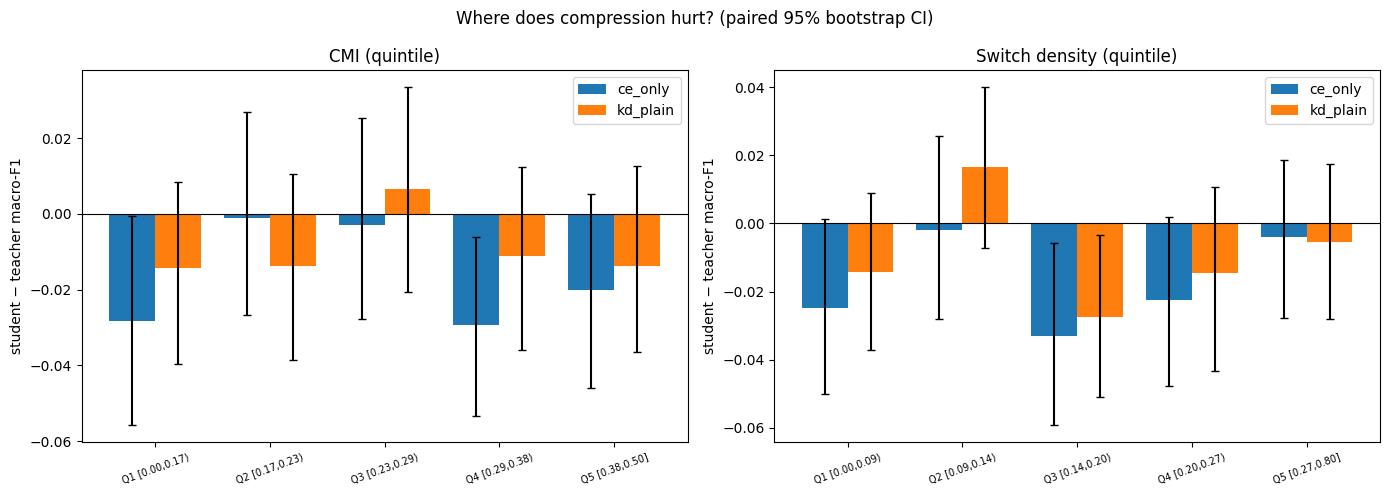

In [13]:
# CELL 11: Figures
plt.figure(figsize=(14, 5))
for pi, nm in enumerate(["CMI (quintile)", "Switch density (quintile)"], start=1):
    plt.subplot(1, 2, pi); t = strat_df[strat_df.cut == nm]; arms = list(PRED_ARM); labs = list(dict.fromkeys(t.bin)); w = 0.8 / max(1, len(arms))
    for ai, a in enumerate(arms):
        ta = t[t.arm == a].set_index("bin").loc[labs]
        plt.bar(np.arange(len(labs)) + ai * w, ta.delta, w, yerr=[ta.delta - ta.delta_lo, ta.delta_hi - ta.delta], capsize=3, label=a)
    plt.axhline(0, color="k", lw=0.8); plt.xticks(np.arange(len(labs)) + w * (len(arms) - 1) / 2, labs, fontsize=7, rotation=20)
    plt.ylabel("student − teacher macro-F1"); plt.title(nm); plt.legend()
plt.suptitle("Where does compression hurt? (paired 95% bootstrap CI)"); plt.tight_layout()
plt.savefig(OUT_DIR / "figures" / "student_vs_teacher_by_bin.png", dpi=150, bbox_inches="tight"); plt.show()

In [14]:
# CELL 12: Preliminary CPU latency (PyTorch fp32, batch 1) — real ONNX/int8 numbers come in Phase 5
import statistics
torch.set_num_threads(min(4, os.cpu_count() or 1))
sample = te_df.sample(100, random_state=0).text.tolist()
def cpu_latency(model, use_remap):
    model = model.to("cpu").eval(); remap_c = torch.tensor(remap_np); times = []
    with torch.no_grad():
        for i, t in enumerate(sample + sample[:10]):
            e = tok(t, truncation=True, max_length=MAXLEN, return_tensors="pt")
            ids = remap_c[e["input_ids"]] if use_remap else e["input_ids"]
            kw = {"input_ids": ids, "attention_mask": e["attention_mask"]}
            if "token_type_ids" in e: kw["token_type_ids"] = e["token_type_ids"]
            t0 = time.perf_counter(); model(**kw); dt = (time.perf_counter() - t0) * 1000
            if i >= 10: times.append(dt)
    return statistics.median(times), float(np.percentile(times, 90))
print("=" * 70); print("════ REPORT BACK: PRELIMINARY CPU LATENCY (batch=1, fp32, PyTorch) ════"); print("=" * 70)
lat = {}
teacher_cpu = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR)
lat["teacher"] = cpu_latency(teacher_cpu, False); print(f"teacher: median {lat['teacher'][0]:.1f} ms, p90 {lat['teacher'][1]:.1f} ms  (threads={torch.get_num_threads()})")
for a in RUN_ARMS:
    sdir = OUT_DIR / f"student_{a}_best"
    if sdir.exists():
        m = AutoModelForSequenceClassification.from_pretrained(sdir); lat[a] = cpu_latency(m, True)
        print(f"{a}: median {lat[a][0]:.1f} ms, p90 {lat[a][1]:.1f} ms -> {lat['teacher'][0] / lat[a][0]:.2f}x faster than teacher")
print("Colab CPUs are small and noisy; treat this as a sanity check on the 6-layer speedup, not a benchmark.")

════ REPORT BACK: PRELIMINARY CPU LATENCY (batch=1, fp32, PyTorch) ════


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

teacher: median 128.8 ms, p90 159.2 ms  (threads=2)


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

ce_only: median 64.4 ms, p90 77.7 ms -> 2.00x faster than teacher


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

kd_plain: median 66.3 ms, p90 80.3 ms -> 1.94x faster than teacher
Colab CPUs are small and noisy; treat this as a sanity check on the 6-layer speedup, not a benchmark.


In [15]:
# CELL 13: Save + summary
overall.to_csv(OUT_DIR / "student_overall.csv", index=False); strat_df.to_csv(OUT_DIR / "student_vs_teacher_by_bin.csv", index=False)
for a, p in PROBS_ARM.items(): np.save(OUT_DIR / f"probs_{a}_all_seeds.npy", p)
summary = {"arms": RUN_ARMS, "seeds": SEEDS, "layer_map": LAYER_MAP, "trim_vocab": TRIM_VOCAB, "vocab_kept": int(len(kept)),
           "test_unk_from_trimming": oov, "teacher_params": int(t_par), "student_params": int(s_par), "n_transfer": int(len(transfer)),
           "epochs": EPOCHS, "lr": LR, "temp": TEMP, "teacher_seed": BEST_T_SEED, "teacher_test_f1": t_f1,
           "student_test_f1": {a: float(np.mean([macro_f1_np(y_te, PRED_ARM[a][k]) for k in range(PRED_ARM[a].shape[0])])) for a in PRED_ARM},
           "cpu_latency_ms_median": {k: v[0] for k, v in lat.items()}}
(OUT_DIR / "phase3_summary.json").write_text(json.dumps(summary, indent=2))
print("=" * 70); print("════ PHASE 3 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════"); print("=" * 70)
print(json.dumps(summary, indent=2)); print(f"\nSaved to: {OUT_DIR}")

════ PHASE 3 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════
{
  "arms": [
    "ce_only",
    "kd_plain"
  ],
  "seeds": [
    13,
    42,
    2024
  ],
  "layer_map": [
    1,
    3,
    5,
    7,
    9,
    11
  ],
  "trim_vocab": true,
  "vocab_kept": 12470,
  "test_unk_from_trimming": 0.045897958273231516,
  "teacher_params": 109484547,
  "student_params": 53093379,
  "n_transfer": 37584,
  "epochs": 3,
  "lr": 5e-05,
  "temp": 2.0,
  "teacher_seed": 2024,
  "teacher_test_f1": 0.7337417057843415,
  "student_test_f1": {
    "ce_only": 0.7162523405409759,
    "kd_plain": 0.7237448610042351
  },
  "cpu_latency_ms_median": {
    "teacher": 128.8443804999133,
    "ce_only": 64.40530800000488,
    "kd_plain": 66.34905150008308
  }
}

Saved to: /content/phase3_outputs
